# 01 — Data Overview

Universe coverage, missing data, price/volume sanity checks, weekly return
distribution, and the universe vs SPY comparison. All data comes from the
same `src/data.py` code path as `main.py` (yfinance weekly bars, 50
tickers, 5 years; cached under `data/`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import data as data_mod
from src import features as feat_mod
from src import models as models_mod
from src import simulate as sim_mod
from src.target import make_target, time_split

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 5)

# Same parameters as the fuller main.py run (50 tickers, 5 years).
# Downloads are cached under data/ (7-day freshness), so re-running is fast.
tickers = data_mod.get_universe(n=50)
prices = data_mod.download_prices(tickers, years=5)
macro = data_mod.download_macro(years=5)
french = data_mod.download_french_weekly()
spy = data_mod.download_benchmark(years=5)

Universe: 503 tickers from Wikipedia S&P 500 list.
Prices: using cache /home/hatch/workspace/stock-markets-analytics-project/data/prices_weekly.parquet
Macro: using cache /home/hatch/workspace/stock-markets-analytics-project/data/macro_weekly.parquet
French factors: using cache /home/hatch/workspace/stock-markets-analytics-project/data/french_weekly.parquet
Benchmark: using cache /home/hatch/workspace/stock-markets-analytics-project/data/spy_weekly.parquet


## Universe coverage

In [2]:
print(f"Tickers: {prices['ticker'].nunique()}")
print(f"Weeks: {prices['date'].nunique()} "
      f"({prices['date'].min().date()} -> {prices['date'].max().date()})")
print(f"Rows: {len(prices):,}")
rows_per_ticker = prices.groupby('ticker').size()
print(rows_per_ticker.describe())
print("\nTickers with the fewest weeks (recent IPOs / gaps):")
print(rows_per_ticker.nsmallest(5))

Tickers: 50
Weeks: 262 (2021-11-22 -> 2026-11-23)
Rows: 13,100
count     50.0
mean     262.0
std        0.0
min      262.0
25%      262.0
50%      262.0
75%      262.0
max      262.0
dtype: float64

Tickers with the fewest weeks (recent IPOs / gaps):
ticker
A       262
AAPL    262
ABBV    262
ABNB    262
ABT     262
dtype: int64


## Missing data

A week is "missing" for a ticker if it has no bar in that week. Recent
IPOs legitimately start late; anything else is a data gap worth knowing
about before modelling.

Missing cells: 0 of 13,100 (0.00%)


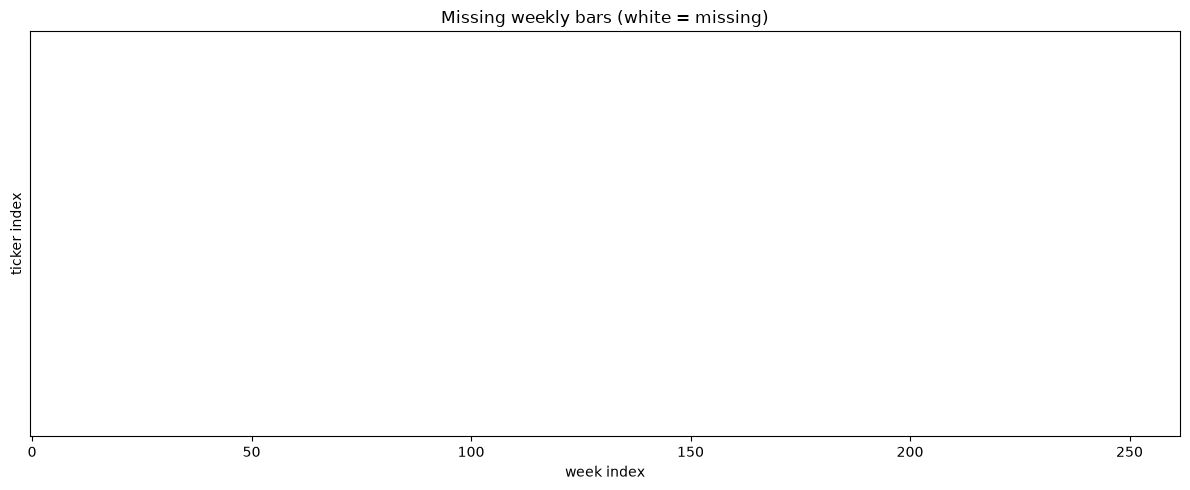

In [3]:
piv = prices.pivot(index='date', columns='ticker', values='close')
missing = piv.isna()
print(f"Missing cells: {missing.sum().sum():,} of {missing.size:,} "
      f"({100 * missing.mean().mean():.2f}%)")
fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(missing.T.values, aspect='auto', cmap='Greys', interpolation='nearest')
ax.set_title('Missing weekly bars (white = missing)')
ax.set_xlabel('week index')
ax.set_ylabel('ticker index')
ax.set_yticks([])
plt.tight_layout()
plt.show()

## Price / volume sanity checks

In [4]:
print(prices[['open', 'high', 'low', 'close', 'volume']].describe().T)
# Suspicious bars: weekly moves over +-40% are usually splits or bad ticks
# (yfinance auto-adjusts for splits, so survivors are genuine jumps).
prices = prices.sort_values(['ticker', 'date'])
prices['wk_ret'] = prices.groupby('ticker')['close'].pct_change()
big = prices[prices['wk_ret'].abs() > 0.40].sort_values('wk_ret')
print(f"\nWeeks with |return| > 40%: {len(big)}")
print(big[['date', 'ticker', 'close', 'wk_ret']].head(10).to_string(index=False))

          count          mean           std            min           25%           50%           75%           max
open    13100.0  1.490146e+02  1.071023e+02       9.106669  7.336859e+01  1.235837e+02  1.934655e+02  7.319700e+02
high    13100.0  1.539199e+02  1.110716e+02       9.483454  7.554888e+01  1.275206e+02  2.007622e+02  7.456100e+02
low     13100.0  1.442439e+02  1.031022e+02       8.732550  7.120026e+01  1.199167e+02  1.880154e+02  7.082000e+02
close   13100.0  1.491557e+02  1.070022e+02       9.061047  7.341112e+01  1.236361e+02  1.942562e+02  7.213700e+02
volume  13100.0  4.063136e+07  7.844533e+07  573300.000000  6.591570e+06  1.293835e+07  2.950745e+07  7.692992e+08

Weeks with |return| > 40%: 3
      date ticker      close   wk_ret
2026-05-04   AKAM 147.710007 0.422066
2026-11-02    APP 391.220001 0.712123
2024-11-04    APP 290.010010 0.773436


## Weekly return distribution — fat tails?

mean 0.2496%, std 4.7664%, skew 0.67, kurtosis 12.72
1st pct -12.38%, 99th pct 13.35%


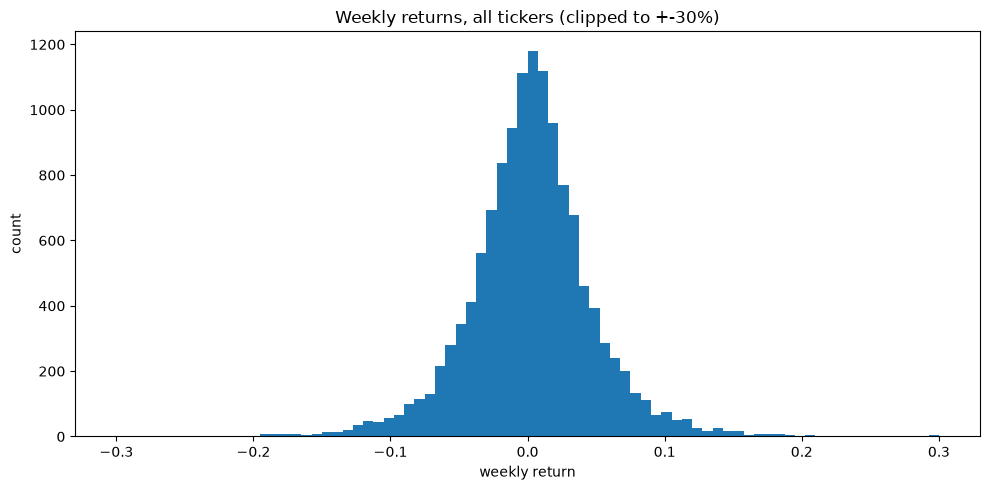

In [5]:
rets = prices['wk_ret'].dropna()
print(f"mean {rets.mean():.4%}, std {rets.std():.4%}, "
      f"skew {rets.skew():.2f}, kurtosis {rets.kurtosis():.2f}")
print(f"1st pct {rets.quantile(0.01):.2%}, 99th pct {rets.quantile(0.99):.2%}")
fig, ax = plt.subplots()
ax.hist(rets.clip(-0.3, 0.3), bins=80)
ax.set_title('Weekly returns, all tickers (clipped to +-30%)')
ax.set_xlabel('weekly return')
ax.set_ylabel('count')
plt.tight_layout()
plt.show()

## Universe vs SPY

In [6]:
uni_weekly = prices.groupby('date')['wk_ret'].mean().rename('universe_mean')
cmp = pd.DataFrame({'universe_mean': uni_weekly}).join(
    spy.set_index('date')['spy_ret'])
cmp = cmp.dropna()
print(cmp.describe().T)
print(f"\nCorrelation(universe mean weekly return, SPY): "
      f"{cmp['universe_mean'].corr(cmp['spy_ret']):.3f}")
print(f"Universe mean weekly return: {cmp['universe_mean'].mean():.4%}")
print(f"SPY mean weekly return:      {cmp['spy_ret'].mean():.4%}")

               count      mean       std       min       25%       50%       75%       max
universe_mean  261.0  0.002496  0.023192 -0.094746 -0.011780  0.003010  0.014897  0.070406
spy_ret        261.0  0.002249  0.023332 -0.090667 -0.012567  0.003366  0.015706  0.066201

Correlation(universe mean weekly return, SPY): 0.925
Universe mean weekly return: 0.2496%
SPY mean weekly return:      0.2249%
